In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
import glob
import os

# --- Paper figure style ---
# A4 paper, 1.1in margins → text width ≈ 6.07 inches
# 11pt LaTeX document
TEXT_WIDTH = 6.07  # inches
FIGS_DIR = '../figs'
os.makedirs(FIGS_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'lines.linewidth': 0.8,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.major.size': 2,
    'ytick.major.size': 2,
    'figure.dpi': 200,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.02,
})

# --- Load combined sweep results ---
results_dir = '/n/holylabs/kempner_dgc_lab/Lab/dclark/cavity_cov_combined_results/'
files = sorted(glob.glob(os.path.join(results_dir, 'results_*.npz')))

catalog = {}
for f in files:
    if os.path.getsize(f) < 1000:
        continue
    try:
        d = np.load(f, allow_pickle=False)
        key = (int(d['N']), float(d['g']), int(d['sampling_ratio']), int(d['run_idx']))
        catalog[key] = f
    except Exception:
        continue

# --- Load high-alpha residual results ---
highalpha_dir = '/n/holylabs/kempner_dgc_lab/Lab/dclark/cavity_cov_residual_highalpha/'
highalpha_files = sorted(glob.glob(os.path.join(highalpha_dir, 'residual_*.npz')))

catalog_highalpha = {}
for f in highalpha_files:
    if os.path.getsize(f) < 1000:
        continue
    try:
        d = np.load(f, allow_pickle=False)
        key = (int(d['N']), float(d['g']), int(d['sampling_ratio']), int(d['run_idx']))
        catalog_highalpha[key] = f
    except Exception:
        continue

# --- Collect metadata ---
g_values = sorted(set(g for (N, g, ratio, run) in catalog))
N_values_all = sorted(set(N for (N, g, ratio, run) in catalog))
alpha_values_combined = sorted(set(ratio for (N, g, ratio, run) in catalog))
alpha_values_highalpha = sorted(set(ratio for (N, g, ratio, run) in catalog_highalpha))
alpha_values_all = sorted(set(alpha_values_combined) | set(alpha_values_highalpha))

# N values for diagnostic plots: start at index 2 (N=464) → 5 panels
N_values_diag = N_values_all[2:]  # [464, 1000, 2154, 4642, 10000]
ALPHA_DIAG = max(alpha_values_combined)    # 800

print(f'g values: {g_values}')
print(f'All N values: {N_values_all}')
print(f'Diagnostic N values: {N_values_diag}')
print(f'Combined alpha values: {alpha_values_combined}')
print(f'High-alpha values: {alpha_values_highalpha}')
print(f'All alpha values: {alpha_values_all}')
print(f'Diagnostic alpha: {ALPHA_DIAG}')
print(f'Total combined files: {len(catalog)}')
print(f'Total high-alpha files: {len(catalog_highalpha)}')

# Color palettes
colors_alpha = {
    50: '#2a9d8f',
    200: '#264653',
    800: '#e76f51',
    3200: '#7b2d8e',
    12800: '#d4a017',
}
# C_ij(tau) pairs: muted but distinct
COLORS_PAIRS = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']

g values: [1.5, 2.5]
All N values: [100, 215, 464, 1000, 2154, 4642, 10000]
Diagnostic N values: [464, 1000, 2154, 4642, 10000]
Combined alpha values: [50, 200, 800]
High-alpha values: [3200, 12800]
All alpha values: [50, 200, 800, 3200, 12800]
Diagnostic alpha: 800
Total combined files: 418
Total high-alpha files: 70


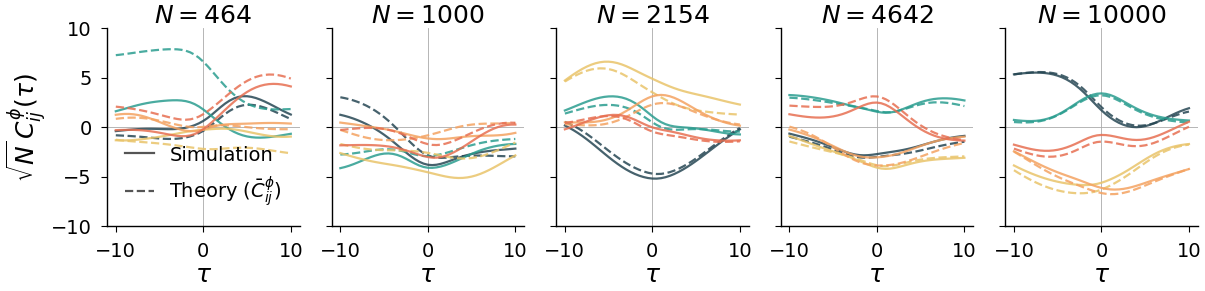

In [2]:
# --- Fig 1: C_ij(tau) diagnostic ---
# 1 row (g=2.5) x 5 cols (N=464..10000), alpha=800
g_plot = 2.5
n_pairs = 5
n_cols = len(N_values_diag)

fig, axes = plt.subplots(1, n_cols, figsize=(TEXT_WIDTH, 1.5),
                         sharey=True, constrained_layout=True)

for col, N in enumerate(N_values_diag):
    ax = axes[col]
    d = None
    for run_idx in range(10):
        key = (N, g_plot, ALPHA_DIAG, run_idx)
        if key in catalog:
            d = np.load(catalog[key], allow_pickle=False)
            break
    if d is None:
        ax.set_visible(False)
        continue

    C_emp = d['C_phi_block']
    C_thy = d['C_theory_block']
    T_save = float(d['T_save'])
    n_lags = int(d['n_lags'])
    B = C_emp.shape[1]
    sqrtN = np.sqrt(N)

    taus_pos = np.arange(n_lags + 1) * T_save
    taus = np.concatenate([-taus_pos[n_lags:0:-1], taus_pos])

    pairs = []
    rng_local = np.random.default_rng(316 + col)
    while len(pairs) < n_pairs:
        i, j = rng_local.integers(B), rng_local.integers(B)
        if i != j:
            pairs.append((i, j))

    for k, (i, j) in enumerate(pairs):
        c = COLORS_PAIRS[k % len(COLORS_PAIRS)]
        emp_neg = C_emp[n_lags:0:-1, j, i]
        emp_full = sqrtN * np.concatenate([emp_neg, C_emp[:, i, j]])
        thy_neg = C_thy[n_lags:0:-1, j, i]
        thy_full = sqrtN * np.concatenate([thy_neg, C_thy[:, i, j]])
        ax.plot(taus, emp_full, '-', color=c, lw=0.8, alpha=0.85)
        ax.plot(taus, thy_full, '--', color=c, lw=0.8, alpha=0.85)

    ax.axhline(0, c='#aaaaaa', lw=0.3, zorder=0)
    ax.axvline(0, c='#aaaaaa', lw=0.3, zorder=0)
    ax.set_title(f'$N = {N}$', pad=2)
    ax.set_xlabel('$\\tau$', labelpad=1)
    ax.set_ylim(-10, 10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('$\\sqrt{N}\\, C^\\phi_{ij}(\\tau)$', labelpad=1)

legend_elements = [
    Line2D([0], [0], color='#555555', ls='-', lw=0.8, label='Simulation'),
    Line2D([0], [0], color='#555555', ls='--', lw=0.8, label='Theory ($\\bar{C}^\\phi_{ij}$)'),
]
axes[0].legend(handles=legend_elements, 
               frameon=False, handlelength=1.5)

plt.savefig(f'{FIGS_DIR}/cij_tau_vs_N.pdf')
plt.show()

In [3]:
import pickle

CACHE_PATH = os.path.join(FIGS_DIR, '.scaling_cache.pkl')

# Cache version: bump this when changing the data pipeline to force recompute
_CACHE_VERSION = 2

recompute = True
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, 'rb') as f:
        cached = pickle.load(f)
    if isinstance(cached, dict) and cached.get('_version') == _CACHE_VERSION:
        scaling = cached['scaling']
        recompute = False
        print(f'Loaded cached scaling data (v{_CACHE_VERSION}) from {CACHE_PATH}')

if recompute:
    scaling = {}
    for g_plot in g_values:
        scaling[g_plot] = {}
        for alpha in alpha_values_all:
            entry = {'Ns': [], 'rms_res': [], 'rms_abs': [], 'rms_rel': []}

            for N in N_values_all:
                res_seeds, abs_seeds, rel_seeds = [], [], []

                # --- Combined sweep: has full covariance + residual ---
                matching = [(k, catalog[k]) for k in catalog
                            if k[0] == N and k[1] == g_plot and k[2] == alpha]
                for key, fpath in matching:
                    d = np.load(fpath, allow_pickle=False)
                    C_emp = d['C_phi_block'][0]
                    C_thy = d['C_theory_block'][0]
                    C_res = d['C_res_0_block']
                    B = C_emp.shape[0]
                    mask = ~np.eye(B, dtype=bool)

                    rms_res = np.sqrt(np.mean(C_res[mask]**2))
                    diff = (C_thy - C_emp)[mask]
                    rms = np.sqrt(np.mean(diff**2))
                    rms_emp = np.sqrt(np.mean(C_emp[mask]**2))

                    if rms / max(rms_emp, 1e-12) > 10:
                        continue

                    res_seeds.append(rms_res)
                    abs_seeds.append(rms)
                    rel_seeds.append(rms / rms_emp)

                # --- High-alpha residual: only has C_res ---
                matching_ha = [(k, catalog_highalpha[k]) for k in catalog_highalpha
                               if k[0] == N and k[1] == g_plot and k[2] == alpha]
                for key, fpath in matching_ha:
                    d = np.load(fpath, allow_pickle=False)
                    C_res = d['C_res_0_block']
                    B = C_res.shape[0]
                    mask = ~np.eye(B, dtype=bool)
                    rms_res = np.sqrt(np.mean(C_res[mask]**2))
                    res_seeds.append(rms_res)

                if len(res_seeds) < 2:
                    continue
                entry['Ns'].append(N)
                entry['rms_res'].append(res_seeds)
                entry['rms_abs'].append(abs_seeds)  # may be empty for high-alpha-only
                entry['rms_rel'].append(rel_seeds)

            entry['Ns'] = np.array(entry['Ns'])
            scaling[g_plot][alpha] = entry

    with open(CACHE_PATH, 'wb') as f:
        pickle.dump({'_version': _CACHE_VERSION, 'scaling': scaling}, f)
    print(f'Computed and cached scaling data (v{_CACHE_VERSION}) to {CACHE_PATH}')

# Print summary
for g_plot in g_values:
    for alpha in alpha_values_all:
        s = scaling[g_plot][alpha]
        if len(s['Ns']):
            n_seeds_res = [len(v) for v in s['rms_res']]
            n_seeds_abs = [len(v) for v in s['rms_abs']]
            print(f'  g={g_plot}, alpha={alpha}: {len(s["Ns"])} N values, '
                  f'N in [{s["Ns"].min()}, {s["Ns"].max()}], '
                  f'res seeds={n_seeds_res}, abs seeds={n_seeds_abs}')
print(f'\nTo recompute, delete {CACHE_PATH}')

Loaded cached scaling data (v2) from ../figs/.scaling_cache.pkl
  g=1.5, alpha=50: 7 N values, N in [100, 10000], res seeds=[10, 10, 8, 9, 10, 10, 10], abs seeds=[10, 10, 8, 9, 10, 10, 10]
  g=1.5, alpha=200: 7 N values, N in [100, 10000], res seeds=[10, 10, 9, 10, 10, 10, 10], abs seeds=[10, 10, 9, 10, 10, 10, 10]
  g=1.5, alpha=800: 7 N values, N in [100, 10000], res seeds=[7, 10, 9, 10, 10, 8, 9], abs seeds=[7, 10, 9, 10, 10, 8, 9]
  g=2.5, alpha=50: 7 N values, N in [100, 10000], res seeds=[8, 9, 9, 10, 10, 10, 10], abs seeds=[8, 9, 9, 10, 10, 10, 10]
  g=2.5, alpha=200: 7 N values, N in [100, 10000], res seeds=[9, 10, 10, 9, 10, 10, 10], abs seeds=[9, 10, 10, 9, 10, 10, 10]
  g=2.5, alpha=800: 7 N values, N in [100, 10000], res seeds=[10, 10, 9, 10, 10, 10, 9], abs seeds=[10, 10, 9, 10, 10, 10, 9]
  g=2.5, alpha=3200: 7 N values, N in [100, 10000], res seeds=[5, 5, 5, 5, 5, 5, 5], abs seeds=[0, 0, 0, 0, 0, 0, 0]
  g=2.5, alpha=12800: 7 N values, N in [100, 10000], res seeds=[5, 5,

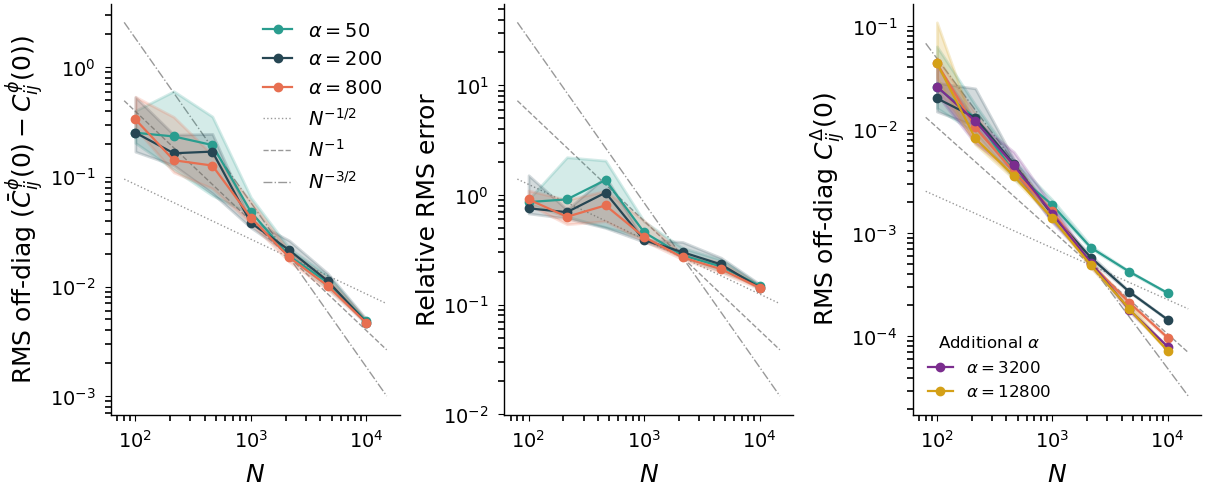

=== g=2.5 ===
  alpha=50:
    N=  100  res=0.025629 (n=8)  abs=0.252946  rel=0.8631  (n=8 seeds)
    N=  215  res=0.012912 (n=9)  abs=0.233938  rel=0.9143  (n=9 seeds)
    N=  464  res=0.003886 (n=9)  abs=0.195308  rel=1.3726  (n=9 seeds)
    N= 1000  res=0.001863 (n=10)  abs=0.048028  rel=0.4584  (n=10 seeds)
    N= 2154  res=0.000722 (n=10)  abs=0.018962  rel=0.2822  (n=10 seeds)
    N= 4642  res=0.000423 (n=10)  abs=0.010837  rel=0.2233  (n=10 seeds)
    N=10000  res=0.000262 (n=10)  abs=0.004832  rel=0.1492  (n=10 seeds)
  alpha=200:
    N=  100  res=0.020057 (n=9)  abs=0.253141  rel=0.7569  (n=9 seeds)
    N=  215  res=0.013012 (n=10)  abs=0.164350  rel=0.6985  (n=10 seeds)
    N=  464  res=0.004645 (n=10)  abs=0.170119  rel=1.0517  (n=10 seeds)
    N= 1000  res=0.001498 (n=9)  abs=0.038120  rel=0.3886  (n=9 seeds)
    N= 2154  res=0.000579 (n=10)  abs=0.021411  rel=0.3018  (n=10 seeds)
    N= 4642  res=0.000270 (n=10)  abs=0.011219  rel=0.2331  (n=10 seeds)
    N=10000  res=0.000

In [4]:
# --- Fig 2: Scaling grid ---
# 1 row (g=2.5) x 3 cols (absolute error, relative error, residual)
# Panels (a), (b): combined-sweep alphas only (need theory prediction)
# Panel (c): all alphas including high-alpha residual-only data

g_plot = 2.5
metrics = [
    ('rms_abs',
     'RMS off-diag $(\\bar{C}^\\phi_{ij}(0) - C^\\phi_{ij}(0))$',
     'Absolute prediction error'),
    ('rms_rel',
     'Relative RMS error',
     'Relative prediction error'),
    ('rms_res',
     'RMS off-diag $C^\\Delta_{ij}(0)$',
     'Residual cross-covariance'),
]
n_cols = len(metrics)
N_ref = np.array([80, 15000])

fig, axes = plt.subplots(1, n_cols, figsize=(TEXT_WIDTH, 2.5),
                         constrained_layout=True)

for col, (metric, ylabel, title) in enumerate(metrics):
    ax = axes[col]

    # For abs/rel error, only show alphas that have prediction data;
    # for residual, show all alphas
    if metric == 'rms_res':
        alphas_to_plot = alpha_values_all
    else:
        alphas_to_plot = alpha_values_combined

    for alpha in alphas_to_plot:
        s = scaling[g_plot].get(alpha)
        if s is None or len(s['Ns']) == 0:
            continue
        vals = s[metric]
        # Skip (N, alpha) points with no data for this metric
        valid = [(N, v) for N, v in zip(s['Ns'], vals) if len(v) >= 2]
        if not valid:
            continue
        Ns = np.array([x[0] for x in valid])
        vals_valid = [x[1] for x in valid]

        medians = np.array([np.median(v) for v in vals_valid])
        q25 = np.array([np.percentile(v, 25) for v in vals_valid])
        q75 = np.array([np.percentile(v, 75) for v in vals_valid])

        ax.fill_between(Ns, q25, q75, alpha=0.2, color=colors_alpha[alpha])
        ax.plot(Ns, medians, 'o-', color=colors_alpha[alpha], ms=2.5, lw=0.8,
                label=f'$\\alpha = {alpha}$')

    # Reference slopes anchored to max alpha at N[-3]
    ref_alpha = max(alphas_to_plot)
    ref_s = scaling[g_plot].get(ref_alpha)
    if ref_s is not None and len(ref_s['Ns']) > 0:
        ref_vals = ref_s[metric]
        ref_valid = [(N, v) for N, v in zip(ref_s['Ns'], ref_vals) if len(v) >= 2]
        if ref_valid:
            ref_Ns = np.array([x[0] for x in ref_valid])
            ref_meds = np.array([np.median(x[1]) for x in ref_valid])
            idx_ref = max(0, len(ref_Ns) - 3)
            for exp, ls, label in [(-0.5, ':', '$N^{-1/2}$'),
                                    (-1.0, '--', '$N^{-1}$'),
                                    (-1.5, '-.', '$N^{-3/2}$')]:
                coeff = ref_meds[idx_ref] / ref_Ns[idx_ref] ** exp
                ax.loglog(N_ref, coeff * N_ref ** exp, ls=ls, color='#999999',
                          lw=0.5, label=label, zorder=0)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('$N$')
    #ax.set_title(title, pad=2)
    ax.set_ylabel(ylabel, labelpad=1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if col == 0:
        ax.legend(frameon=False, handlelength=1.5)
    elif col == n_cols - 1:
        # Only show the new high-alpha entries; colors for 50/200/800 carry from panel (a)
        handles, labels = ax.get_legend_handles_labels()
        ha_handles = [(h, l) for h, l in zip(handles, labels)
                      if any(f'\\alpha = {a}' in l for a in alpha_values_highalpha)]
        if ha_handles:
            ax.legend([h for h, l in ha_handles], [l for h, l in ha_handles],
                      frameon=False, handlelength=1.5, fontsize=6,
                      title='Additional $\\alpha$', title_fontsize=6, loc='lower left')

plt.savefig(f'{FIGS_DIR}/scaling_grid.pdf')
plt.show()

# Print summary
print(f'=== g={g_plot} ===')
for alpha in alpha_values_all:
    s = scaling[g_plot].get(alpha)
    if s is None or len(s['Ns']) == 0:
        continue
    print(f'  alpha={alpha}:')
    for i, N in enumerate(s['Ns']):
        parts = [f'N={N:5d}']
        parts.append(f'res={np.median(s["rms_res"][i]):.6f} (n={len(s["rms_res"][i])})')
        if len(s['rms_abs'][i]) > 0:
            parts.append(f'abs={np.median(s["rms_abs"][i]):.6f}')
            parts.append(f'rel={np.median(s["rms_rel"][i]):.4f}')
            parts.append(f'(n={len(s["rms_abs"][i])} seeds)')
        print(f'    {"  ".join(parts)}')

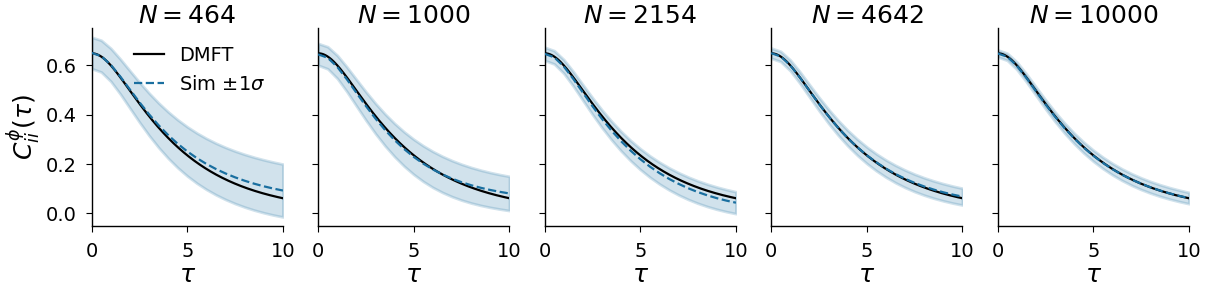

In [5]:
# --- Fig 3 (appendix): Autocorrelation diagnostic (tau domain) ---
# 1 row (g=2.5) x 5 cols (N=464..10000), alpha=800
g_plot = 2.5
n_cols = len(N_values_diag)
SIM_COLOR = '#1a6fa0'

fig, axes = plt.subplots(1, n_cols, figsize=(TEXT_WIDTH, 1.5),
                         sharey=True, constrained_layout=True)

for col, N in enumerate(N_values_diag):
    ax = axes[col]
    d = None
    for run_idx in range(10):
        key = (N, g_plot, ALPHA_DIAG, run_idx)
        if key in catalog:
            d = np.load(catalog[key], allow_pickle=False)
            break
    if d is None:
        ax.set_visible(False)
        continue

    T_save = float(d['T_save'])
    n_lags = int(d['n_lags'])
    tau_vals_dmft = d['tau_vals_dmft']
    C_phi_scalar_dmft = d['C_phi_scalar_dmft']

    C_phi_block = d['C_phi_block']
    B = C_phi_block.shape[1]
    taus = np.arange(n_lags + 1) * T_save

    diag_vals = np.array([C_phi_block[lag].diagonal() for lag in range(n_lags + 1)])
    diag_mean = diag_vals.mean(axis=1)
    diag_std = diag_vals.std(axis=1)

    ax.plot(tau_vals_dmft, C_phi_scalar_dmft, '-', lw=0.8, color='black',
            label='DMFT', zorder=2)
    ax.fill_between(taus, diag_mean - diag_std, diag_mean + diag_std,
                    alpha=0.2, color=SIM_COLOR, zorder=1)
    ax.plot(taus, diag_mean, '--', color=SIM_COLOR, lw=0.8,
            label='Sim $\\pm 1\\sigma$', zorder=3)

    ax.set_xlim(0, taus[-1])
    ax.set_title(f'$N = {N}$', pad=2)
    ax.set_xlabel('$\\tau$', labelpad=1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if col == 0:
        ax.set_ylabel('$C^\\phi_{ii}(\\tau)$', labelpad=1)

axes[0].legend(loc='upper right', frameon=False, handlelength=1.5)

plt.savefig(f'{FIGS_DIR}/autocorrelation_diagnostic.pdf')
plt.show()